In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(0)


In [2]:
real_yield = {
    2000: 940.3,
    2001: 1127.9,
    2002: 743.9,
    2003: 1345.9,
    2004: 992.7
}


In [5]:
def simulate_season():
    # --- Fixed season length ---
    days = 120

    # --- Crop parameters (conservative) ---
    LAI_max = np.random.uniform(4.5, 6.0)
    r = np.random.uniform(0.06, 0.10)        # slightly stronger early growth
    RUE = np.random.uniform(1.3, 1.6)        # g/MJ
    HI = np.random.uniform(0.32, 0.42)

    # --- Season stress (persistent) ---
    stress = np.random.uniform(0.7, 1.0)

    LAI = 0.3          # IMPORTANT: realistic emergence
    biomass = 0.0      # kg/ha

    for _ in range(days):
        PAR = np.random.normal(18, 2)        # MJ/m²/day
        PAR = max(PAR, 5)

        # LAI growth
        LAI = LAI + r * LAI * (1 - LAI / LAI_max) * stress
        LAI = min(LAI, LAI_max)

        # Radiation interception
        IPAR = PAR * (1 - np.exp(-0.6 * LAI))

        # Biomass increment
        dB = RUE * IPAR * stress * 1.0      # g/m² → kg/ha
        biomass += dB

    yield_kg_ha = biomass * HI
    return yield_kg_ha


In [6]:
test_vals = [simulate_season() for _ in range(20)]
test_vals


[np.float64(644.1791829911143),
 np.float64(816.843548862449),
 np.float64(622.8626963469585),
 np.float64(584.2071298294227),
 np.float64(721.8115719418774),
 np.float64(621.1631505283582),
 np.float64(804.4803921106259),
 np.float64(644.7337764124595),
 np.float64(673.7026087951713),
 np.float64(662.6461777254856),
 np.float64(587.3471990014739),
 np.float64(1042.3114286115622),
 np.float64(845.1095558041075),
 np.float64(936.1800381988575),
 np.float64(602.8595066974444),
 np.float64(824.7861079404857),
 np.float64(593.8198365102337),
 np.float64(609.5377517676478),
 np.float64(879.0862796391423),
 np.float64(634.8342315134017)]

In [7]:
YIELD_MIN = 500
YIELD_MAX = 3000

def simulate_year(n=500):
    vals = []
    rejected = 0

    for _ in range(n):
        y = simulate_season()
        if YIELD_MIN <= y <= YIELD_MAX:
            vals.append(y)
        else:
            rejected += 1

    return np.array(vals), rejected


In [8]:
synthetic_results = {}
rejection_stats = {}

for year in real_yield:
    syn, rej = simulate_year(n=500)
    synthetic_results[year] = syn
    rejection_stats[year] = rej

rejection_stats


{2000: 3, 2001: 2, 2002: 5, 2003: 4, 2004: 3}

In [9]:
for year, syn in synthetic_results.items():
    print(
        year,
        "count:", len(syn),
        "min:", round(syn.min(), 1),
        "max:", round(syn.max(), 1),
        "mean:", round(syn.mean(), 1)
    )


2000 count: 497 min: 500.5 max: 1089.6 mean: 754.3
2001 count: 498 min: 519.0 max: 1134.8 mean: 762.2
2002 count: 495 min: 509.2 max: 1161.2 mean: 749.9
2003 count: 496 min: 512.7 max: 1075.7 mean: 757.8
2004 count: 497 min: 522.5 max: 1127.5 mean: 758.9


In [10]:
summary = []

for year, syn in synthetic_results.items():
    summary.append({
        "Year": year,
        "Real_Yield": real_yield[year],
        "P10": round(np.percentile(syn, 10), 1),
        "Median": round(np.percentile(syn, 50), 1),
        "P90": round(np.percentile(syn, 90), 1)
    })

df_validation = pd.DataFrame(summary)
df_validation


,Year,Real_Yield,P10,Median,P90
0,2000,940.3,592.6,749.3,926.7
1,2001,1127.9,604.2,756.9,927.6
2,2002,743.9,597.1,742.6,919.4
3,2003,1345.9,601.5,744.7,924.7
4,2004,992.7,603.9,743.7,925.0


C:\Users\Acer\AppData\Local\Temp\ipykernel_5252\1183362175.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


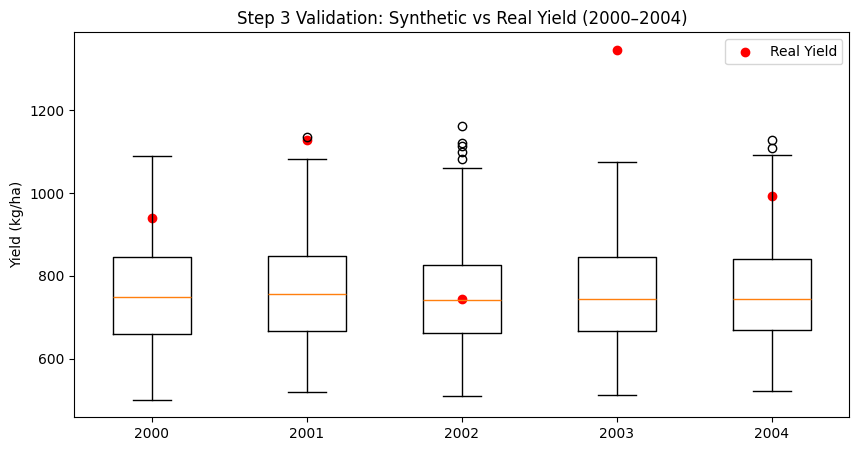

In [11]:
plt.figure(figsize=(10,5))
plt.boxplot(
    [synthetic_results[y] for y in real_yield.keys()],
    labels=real_yield.keys()
)
plt.scatter(
    range(1, 6),
    list(real_yield.values()),
    color="red",
    label="Real Yield"
)
plt.ylabel("Yield (kg/ha)")
plt.title("Step 3 Validation: Synthetic vs Real Yield (2000–2004)")
plt.legend()
plt.show()


In [13]:
real_yield_all = {
    2000: 940.3,
    2001: 1127.9,
    2002: 743.9,
    2003: 1345.9,
    2004: 992.7,
    2005: 1184.5,
    2006: 863.8,
    2007: 1453,
    2008: 1187,
    2009: 983.3,
    2010: 1407.8,
    2011: 1299.2,
    2012: 1030,
    2013: 1759.8,
    2014: 1556.7,
    2015: 1489,
    2016: 1389.1,
    2017: 1838,
    2018: 1444.2,
    2019: 2044.2,
    2020: 1729.1,
    2021: 1763.3,
    2022: 2030.3,
    2023: 2192.1,
    2024: 2111.9
}


In [15]:
df_real = pd.read_csv("groundnut_yield_weather_merged_2000_2024.csv")
# expected columns: Year, yield_kg_per_ha


In [16]:
# Generate global synthetic distribution
global_syn = []

for _ in range(5000):
    y = simulate_season()
    if 500 <= y <= 3000:
        global_syn.append(y)

global_syn = np.array(global_syn)


In [17]:
syn_p10 = np.percentile(global_syn, 10)
syn_p50 = np.percentile(global_syn, 50)
syn_p90 = np.percentile(global_syn, 90)

syn_min = global_syn.min()
syn_max = global_syn.max()

syn_p10, syn_p50, syn_p90, syn_min, syn_max


(np.float64(599.0234952671769),
 np.float64(747.4560316071972),
 np.float64(927.7843904228727),
 np.float64(500.79930026395215),
 np.float64(1169.3702806556578))

In [18]:
coverage = []

for year, y in real_yield_all.items():
    coverage.append({
        "Year": year,
        "Real_Yield": y,
        "Within_P10_P90": syn_p10 <= y <= syn_p90,
        "Within_Min_Max": syn_min <= y <= syn_max
    })

df_coverage = pd.DataFrame(coverage)
df_coverage


,Year,Real_Yield,Within_P10_P90,Within_Min_Max
0,2000,940.3,False,True
1,2001,1127.9,False,True
2,2002,743.9,True,True
3,2003,1345.9,False,False
4,2004,992.7,False,True
5,2005,1184.5,False,False
6,2006,863.8,True,True
7,2007,1453.0,False,False
8,2008,1187.0,False,False
9,2009,983.3,False,True


In [19]:
pct_inside = df_coverage["Within_P10_P90"].mean() * 100
pct_inside, "%"


(np.float64(8.0), '%')

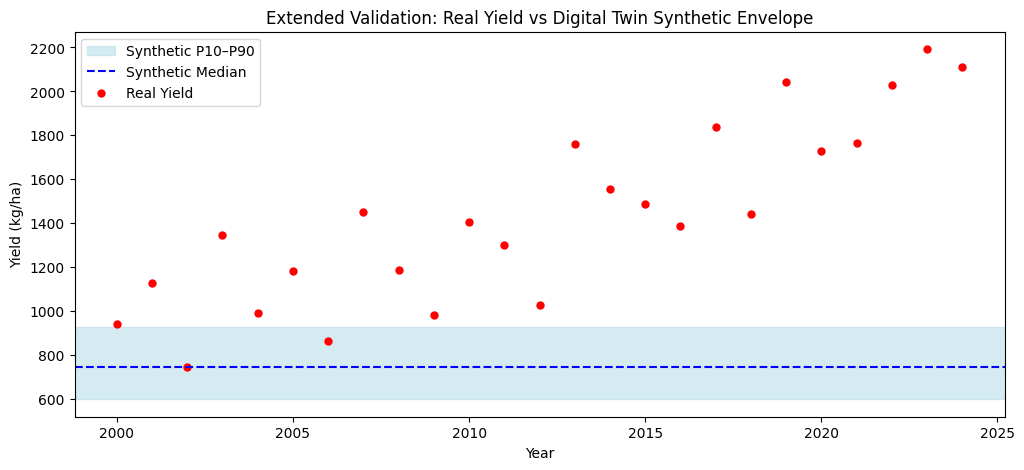

In [20]:
plt.figure(figsize=(12,5))

# Synthetic envelope
plt.axhspan(syn_p10, syn_p90, color="lightblue", alpha=0.5, label="Synthetic P10–P90")
plt.axhline(syn_p50, color="blue", linestyle="--", label="Synthetic Median")

# Real yields
years = list(real_yield_all.keys())
real_vals = list(real_yield_all.values())
plt.scatter(years, real_vals, color="red", s=25, label="Real Yield")

plt.xlabel("Year")
plt.ylabel("Yield (kg/ha)")
plt.title("Extended Validation: Real Yield vs Digital Twin Synthetic Envelope")
plt.legend()
plt.show()
